# Assignment 4: Baseline Predictive Modeling — Lung Cancer Survival Group

Objective: Train and compare three supervised binary classification models to predict 'Survival_Group' ('Short-Term' or 'Long-Term') using the cleaned dataset from Assignment 3.

## 1. Imports and configuration

The notebook uses pandas and NumPy for data handling, matplotlib for plots, and scikit-learn for splitting, preprocessing, models, and metrics.

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, RocCurveDisplay
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
DATA_PATH = "../data/cleaned_dataset_assignment3.csv"

## 2. Load and inspect the dataset


In [41]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("data_type"))
print("\nMissing values (only columns with missing values):")
display(df.isna().sum()[df.isna().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())

if "Survival_Group" not in df.columns:
    raise ValueError("The dataset must contain the target column 'Survival_Group'.")

print("\nTarget counts:")
display(df["Survival_Group"].value_counts().to_frame("count"))
print("\nTarget percentages:")
display((df["Survival_Group"].value_counts(normalize=True) * 100).round(2).to_frame("percent"))

Dataset shape: (23658, 57)


,Age,Tumor_Size_mm,Performance_Status,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Blood_Pressure_Pulse,Hemoglobin_Level,White_Blood_Cell_Count,Platelet_Count,Albumin_Level,...,Survival_Group,Stage,Treatment,Gender,Smoking_History,Age_Group,Tumor_Size_Group,Comorbidity_Count,Treatment_Count,Blood_Pressure_Difference
0,51,30.312823,0,163,78,60,15.610565,3.543686,250.887930,3.731595,...,Short-Term,Stage IV,Surgery,Female,Former Smoker,50-64,Small,3,1,85
1,47,15.668398,3,178,64,93,16.968066,4.137507,210.907856,4.707746,...,Long-Term,Stage IV,Surgery,Female,Current Smoker,30-49,Small,5,1,114
2,71,58.319399,3,96,89,69,13.108920,5.285139,192.435582,4.540101,...,Long-Term,Stage I,Surgery,Female,Never Smoked,65-79,Medium,3,1,7
3,67,67.116956,1,130,85,78,14.898905,7.274861,411.558815,4.095703,...,Long-Term,Stage I,Other,Male,Never Smoked,65-79,Medium,5,0,45
4,69,95.779354,0,167,100,75,15.952222,7.258468,278.649120,3.567760,...,Long-Term,Stage II,Targeted Therapy,Female,Never Smoked,65-79,Large,5,1,67


,data_type
Age,int64
Tumor_Size_mm,float64
Performance_Status,int64
Blood_Pressure_Systolic,int64
Blood_Pressure_Diastolic,int64
Blood_Pressure_Pulse,int64
Hemoglobin_Level,float64
White_Blood_Cell_Count,float64
Platelet_Count,float64
Albumin_Level,float64



Missing values (only columns with missing values):


Series([], dtype: int64)

Duplicate rows: 0

Target counts:


,count
Survival_Group,
Long-Term,11948
Short-Term,11710



Target percentages:


,percent
Survival_Group,
Long-Term,50.5
Short-Term,49.5


## 3. Define the target and predictors

'Survival_Group' is the target ('y'). All other selected columns are predictors ('X'). The raw string columns 'Stage', 'Treatment', 'Gender', and 'Smoking_History' are excluded because the dataset already contains one-hot encoded columns representing those same fields. This avoids duplicate representations of the same information. 'Age_Group' and 'Tumor_Size_Group' are retained as engineered categorical features.

In [42]:
target = "Survival_Group"
y = df[target].copy()

redundant_raw_categories = ["Stage", "Treatment", "Gender", "Smoking_History"]
X = df.drop(columns=[target] + [c for c in redundant_raw_categories if c in df.columns]).copy()

cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X.select_dtypes(include=np.number).columns.tolist()

print("Predictor shape:", X.shape)
print("Numeric predictors:", len(num_cols))
print("Categorical predictors:", cat_cols)
print("Target labels:", sorted(y.dropna().unique().tolist()))

Predictor shape: (23658, 52)
Numeric predictors: 50
Categorical predictors: ['Age_Group', 'Tumor_Size_Group']
Target labels: ['Long-Term', 'Short-Term']


## 4. Train/test split

Used 80% of records for training and 20% for final testing. 'stratify=y' preserves the approximate target-class proportions in both sets. The test set is held aside for final evaluation.

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).round(3).to_frame("proportion"))
print("\nTest target proportions:")
display(y_test.value_counts(normalize=True).round(3).to_frame("proportion"))

Training rows: 18926
Test rows: 4732

Training target proportions:


,proportion
Survival_Group,
Long-Term,0.505
Short-Term,0.495



Test target proportions:


,proportion
Survival_Group,
Long-Term,0.505
Short-Term,0.495


## 5. Preprocessing pipeline

Numerical columns are imputed with the median and standardized. Categorical columns are imputed with the most frequent category and one-hot encoded. These transformations are inside a `ColumnTransformer` and `Pipeline`, so each model learns preprocessing from training data only.

In [44]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, num_cols),
    ("categorical", categorical_pipeline, cat_cols)
])

## 6. Train three baseline classifiers

- **Logistic Regression:** a linear classification baseline.
- **Decision Tree:** a rule-based model; maximum depth and minimum leaf size limit tree complexity.
- **K-Nearest Neighbors (KNN):** predicts from nearby training examples; scaling is important for distance-based models.

The selected hyperparameters are baseline settings, not the result of an exhaustive tuning process.

In [45]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE, max_depth=8, min_samples_leaf=20
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=15, weights="distance"
    )
}

fitted_models = {}
test_predictions = {}
test_probabilities = {}
results = []

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocess", preprocessor),
        ("model", estimator)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    class_labels = list(pipeline.named_steps["model"].classes_)
    long_term_index = class_labels.index("Long-Term")
    y_prob_long = pipeline.predict_proba(X_test)[:, long_term_index]

    fitted_models[name] = pipeline
    test_predictions[name] = y_pred
    test_probabilities[name] = y_prob_long

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (Long-Term)": f1_score(y_test, y_pred, pos_label="Long-Term", zero_division=0),
        "F1 (Short-Term)": f1_score(y_test, y_pred, pos_label="Short-Term", zero_division=0),
        "ROC-AUC (Long-Term)": roc_auc_score(
            (y_test == "Long-Term").astype(int), y_prob_long
        )
    })

results_df = pd.DataFrame(results).sort_values("F1 (macro)", ascending=False)
display(results_df.round(4))

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (Long-Term),F1 (Short-Term),ROC-AUC (Long-Term)
0,Logistic Regression,0.4989,0.4981,0.4982,0.4955,0.5370,0.4541,0.5027
2,K-Nearest Neighbors,0.4934,0.4934,0.4934,0.4934,0.5001,0.4866,0.4979
1,Decision Tree,0.4939,0.4909,0.4921,0.4760,0.5727,0.3794,0.4984


## 7. Detailed classification reports and confusion matrices

The confusion matrix order is explicitly set to `Short-Term`, then `Long-Term`. Rows are actual classes and columns are predicted classes. The class-specific report helps reveal whether a model misses one survival group more often than the other.


Logistic Regression
              precision    recall  f1-score   support

  Short-Term       0.49      0.42      0.45      2342
   Long-Term       0.50      0.58      0.54      2390

    accuracy                           0.50      4732
   macro avg       0.50      0.50      0.50      4732
weighted avg       0.50      0.50      0.50      4732



,Predicted Short-Term,Predicted Long-Term
Actual Short-Term,986,1356
Actual Long-Term,1015,1375


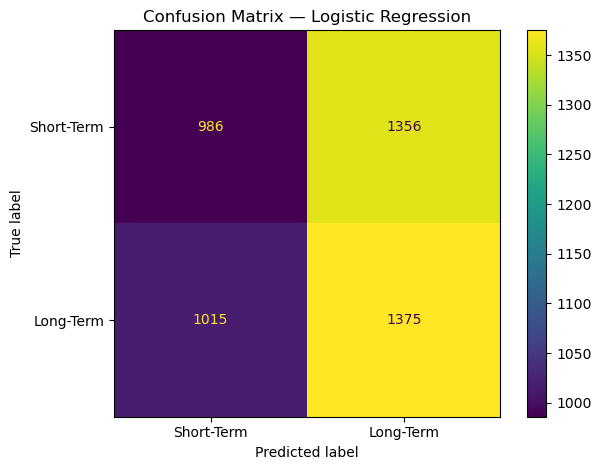


Decision Tree
              precision    recall  f1-score   support

  Short-Term       0.48      0.31      0.38      2342
   Long-Term       0.50      0.67      0.57      2390

    accuracy                           0.49      4732
   macro avg       0.49      0.49      0.48      4732
weighted avg       0.49      0.49      0.48      4732



,Predicted Short-Term,Predicted Long-Term
Actual Short-Term,732,1610
Actual Long-Term,785,1605


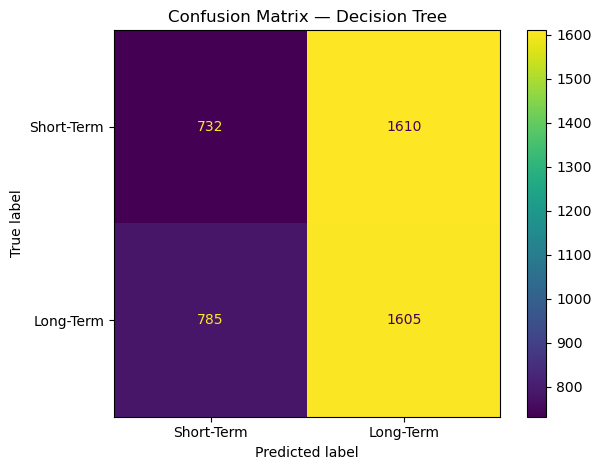


K-Nearest Neighbors
              precision    recall  f1-score   support

  Short-Term       0.49      0.49      0.49      2342
   Long-Term       0.50      0.50      0.50      2390

    accuracy                           0.49      4732
   macro avg       0.49      0.49      0.49      4732
weighted avg       0.49      0.49      0.49      4732



,Predicted Short-Term,Predicted Long-Term
Actual Short-Term,1136,1206
Actual Long-Term,1191,1199


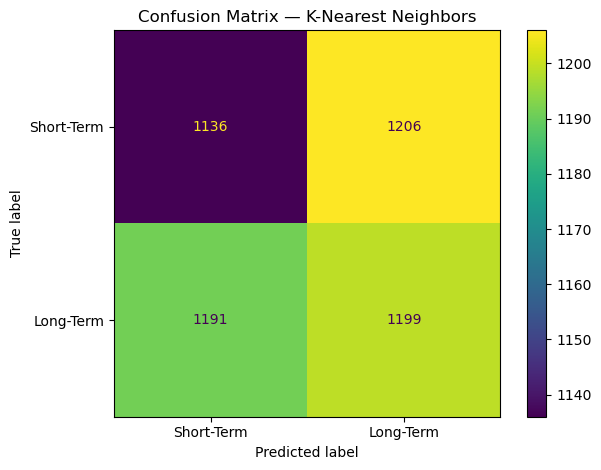

In [46]:
for name, y_pred in test_predictions.items():
    print("\n", "=" * 70)
    print(name)
    print(classification_report(
        y_test, y_pred, labels=["Short-Term", "Long-Term"], zero_division=0
    ))
    cm = confusion_matrix(y_test, y_pred, labels=["Short-Term", "Long-Term"])
    display(pd.DataFrame(
        cm,
        index=["Actual Short-Term", "Actual Long-Term"],
        columns=["Predicted Short-Term", "Predicted Long-Term"]
    ))
    ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=["Short-Term", "Long-Term"]
    ).plot()
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

## 8. ROC curves and AUC

The positive class is defined as 'Long-Term'. ROC-AUC measures how well predicted scores rank the two classes over possible thresholds; a value near 0.50 indicates discrimination close to chance.

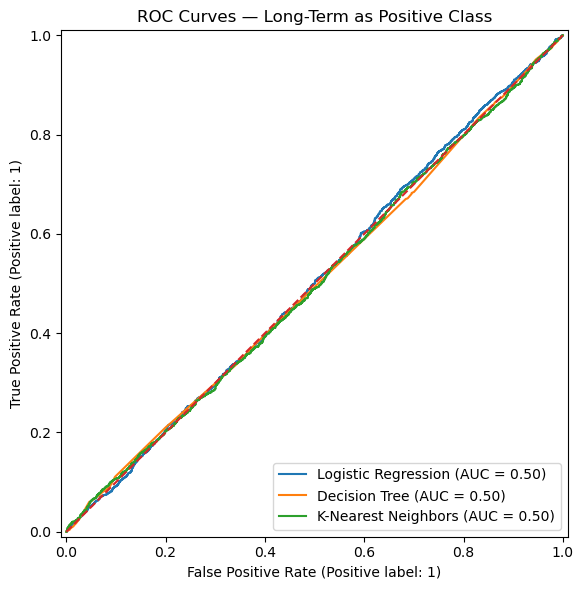

In [47]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, pipeline in fitted_models.items():
    RocCurveDisplay.from_predictions(
        (y_test == "Long-Term").astype(int),
        test_probabilities[name],
        name=name,
        ax=ax
    )
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance reference")
ax.set_title("ROC Curves — Long-Term as Positive Class")
plt.tight_layout()
plt.show()

## 9. Cross-validation on training data

Three-fold stratified cross-validation provides an additional stability check without using the held-out test set for model selection. Scores can vary across folds, and three folds are a baseline rather than an exhaustive tuning procedure.

In [48]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipeline in fitted_models.items():
    scores = cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1
    )
    cv_rows.append({
        "Model": name,
        "CV macro-F1 mean": scores.mean(),
        "CV macro-F1 SD": scores.std(),
        "Fold scores": np.round(scores, 4).tolist()
    })
cv_df = pd.DataFrame(cv_rows)
display(cv_df)

,Model,CV macro-F1 mean,CV macro-F1 SD,Fold scores
0,Logistic Regression,0.498951,0.006547,"[0.4924, 0.4966, 0.5079]"
1,Decision Tree,0.478199,0.007100,"[0.4854, 0.4806, 0.4685]"
2,K-Nearest Neighbors,0.502900,0.002448,"[0.5062, 0.5003, 0.5022]"


## 10. Error analysis: five actual misclassifications

The notebook selects five test-set errors from the model with the highest test macro-F1 among these baseline models. The displayed row number is not a patient identifier. Interpretations are hypotheses based on available features; a wrong prediction does not necessarily have a single identifiable cause.

In [49]:
best_model_name = results_df.iloc[0]["Model"]
best_pred = test_predictions[best_model_name]

error_table = X_test.copy()
error_table["Actual"] = y_test
error_table["Predicted"] = best_pred
error_table = error_table[error_table["Actual"] != error_table["Predicted"]]

error_columns = [
    c for c in [
        "Age", "Tumor_Size_mm", "Performance_Status",
        "Stage_Stage II", "Stage_Stage III", "Stage_Stage IV",
        "Treatment_Surgery", "Treatment_Radiation Therapy",
        "Treatment_Targeted Therapy", "Comorbidity_Count",
        "Treatment_Count", "Blood_Pressure_Difference",
        "Age_Group", "Tumor_Size_Group"
    ] if c in error_table.columns
]
display(error_table[["Actual", "Predicted"] + error_columns].head(5))
print("Total test-set misclassifications for selected model:", len(error_table))

,Actual,Predicted,Age,Tumor_Size_mm,Performance_Status,Stage_Stage II,Stage_Stage III,Stage_Stage IV,Treatment_Surgery,Treatment_Radiation Therapy,Treatment_Targeted Therapy,Comorbidity_Count,Treatment_Count,Blood_Pressure_Difference,Age_Group,Tumor_Size_Group
1232,Long-Term,Short-Term,47,14.591022,1,0,1,0,1,0,0,3,1,64,30-49,Small
14191,Long-Term,Short-Term,65,52.993438,2,0,1,0,0,0,1,4,1,16,65-79,Medium
22850,Long-Term,Short-Term,58,90.739909,3,0,0,1,0,1,0,3,1,89,50-64,Large
18800,Short-Term,Long-Term,55,93.746326,2,0,0,1,0,1,0,3,1,67,50-64,Large
1585,Short-Term,Long-Term,33,87.975404,3,0,1,0,1,0,0,5,1,70,30-49,Large


Total test-set misclassifications for selected model: 2371


## 11. Feature importance (permutation importance)

Permutation importance estimates how much a metric changes when a feature is shuffled. It is computed on a sample of held-out test rows to reduce computation. Results can be noisy, and correlated features can share or obscure importance; do not interpret this as causal evidence.

In [50]:
sample_n = min(1500, len(X_test))
X_importance = X_test.sample(n=sample_n, random_state=RANDOM_STATE)
y_importance = y_test.loc[X_importance.index]

perm = permutation_importance(
    fitted_models[best_model_name],
    X_importance,
    y_importance,
    scoring="f1_macro",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance mean": perm.importances_mean,
    "Importance SD": perm.importances_std
}).sort_values("Importance mean", ascending=False)
display(importance_df.head(15))

,Feature,Importance mean,Importance SD
35,Ethnicity_Other,0.012268,0.002847
28,Stage_Stage IV,0.011092,0.003366
40,Comorbidity_Diabetes_Yes,0.008689,0.003089
24,Tumor_Location_Middle Lobe,0.007665,0.005668
23,Smoking_History_Never Smoked,0.002853,0.001705
5,Blood_Pressure_Pulse,0.002842,0.008738
16,Phosphorus_Level,0.002410,0.001794
3,Blood_Pressure_Systolic,0.001387,0.002464
22,Smoking_History_Former Smoker,0.001103,0.002073
30,Treatment_Surgery,0.000863,0.002993


## 12. Discussion of Model Limitations

In this project, we tested three baseline models: Logistic Regression, Decision Tree, and K-Nearest Neighbors (KNN) to predict lung cancer survival groups. Based on our results, all three models achieved an accuracy of around 49–50%, with macro-F1 scores close to 0.50. This shows that the models had difficulty correctly predicting whether a patient belonged to the Short-Term or Long-Term survival group.

There are a few limitations to consider in this project:

Low model performance: The accuracy of all three models was relatively low, which means their predictions were not very reliable. The results suggest that the models were not able to identify clear patterns in the data that could help predict survival groups accurately.

Misclassification of patients: The confusion matrices showed that the models made mistakes when predicting both survival groups. This means that the models struggled to distinguish between patients with different survival outcomes.

Limited parameter tuning: We mainly used baseline model settings in this project. We did not fully explore different hyperparameter combinations, so the models may not have been performing at their best.

Limitations of the available features: Even though the dataset contained many records and features, the information available may not have been enough to predict survival groups accurately. Other clinical factors that were not included in the dataset might also affect survival outcomes.

Limited validation: We used three-fold stratified cross-validation to evaluate the models. Although this helped us check their performance across different data splits, additional testing would be needed to determine how well the models perform on new and unseen data.

Overall, this project helped us understand that choosing a machine learning model alone does not guarantee good results. The quality of the data, the selected features, and the model settings can all affect performance. Since our models achieved relatively low scores, their predictions should not be considered reliable enough for real-world medical decisions.

# 13 Recommendations for Future Improvements 
Based on the results of our baseline models, there are several ways we could improve this project in the future.

Check the dataset and target variable: We should take a closer look at how the Short-Term and Long-Term survival groups were defined and make sure the data is consistent. We should also check for missing values, unusual values, and possible data leakage that could affect the results.

Tune the model parameters: Instead of using only the default settings, we could use Grid Search or Randomized Search to find better parameters for each model. For example, we could adjust the tree depth in Decision Tree, the number of neighbors in KNN, and the regularization settings in Logistic Regression.

Try other machine learning models: In future work, we could test models such as Random Forest, Gradient Boosting, or XGBoost. These models may be able to identify patterns in the data that the three baseline models could not capture.

Improve feature selection: We could investigate which features are most useful for predicting survival groups and remove unnecessary or highly redundant features when appropriate. We could also explore creating new features that might help the models make better predictions.

Evaluate models using different metrics: We should not rely on accuracy alone. Comparing precision, recall, macro-F1, and ROC-AUC, where appropriate, would give us a better understanding of how well each model predicts the two survival groups. We should also examine the confusion matrices to understand which predictions are most often incorrect.

Compare against a simple baseline: We could compare our models with a basic classifier that always predicts the majority class. This would help us determine whether our machine learning models are actually learning useful patterns from the dataset.

Test the models on new data: If another suitable dataset is available, we could use it to evaluate the best-performing model. This would help us understand whether the model can make similar predictions for patients outside the original dataset.

Understand the model predictions: We could use feature-importance methods or other interpretation techniques to better understand which variables influence the predictions. This would help us explain the results more clearly, although the identified relationships would not necessarily mean that a feature causes a particular survival outcome.

In conclusion, our next step would be to improve the data analysis, experiment with different model settings, and compare additional algorithms. Since the current models achieved only around 49–50% accuracy, there is room for improvement. This project gave us a useful starting point for understanding machine learning classification, and further testing would help us determine whether better performance is possible. Any future model intended for healthcare use would also need independent validation before it could be considered reliable for clinical decisions.